Device: cuda; model: bert-base-uncased; full train pool: 25,000; max_length=64; batch_size=16; epochs=1


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (25 outputs left out)

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 100% | n=25000 | train_loss=0.4210 | val_acc=0.8280 val_f1=0.8294 | test_acc=0.8460 test_f1=0.8466 | train=318.2s

BẢNG KẾT QUẢ TEST — validation/test giữ cố định (mỗi tập 1,000 mẫu, cân bằng nhãn)
Train data | N train | Accuracy | F1 | Training time (s)
     10% |    2500 | 0.8240 | 0.8215 | 30.0
     25% |    6250 | 0.8420 | 0.8410 | 78.6
     50% |   12500 | 0.8440 | 0.8351 | 159.4
    100% |   25000 | 0.8460 | 0.8466 | 318.2


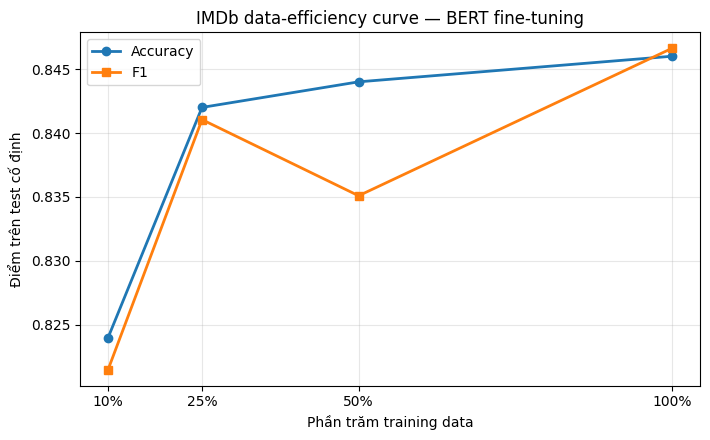

Accuracy theo 10/25/50/100%: [0.824, 0.842, 0.844, 0.846]
F1 theo 10/25/50/100%: [0.8215, 0.841, 0.8351, 0.8466]
Diễn giải: cần đọc toàn bộ đường cong; nếu các điểm tăng nhìn chung khi thêm dữ liệu thì đây là bằng chứng BERT khai thác thêm nhãn downstream. Muốn khẳng định pretrained tiết kiệm dữ liệu hơn scratch một cách nhân quả, cần chạy baseline from-scratch trên cùng các mức và split.


In [ ]:
%pip -q install datasets scikit-learn matplotlib

# Bài 16: Ảnh hưởng của lượng dữ liệu huấn luyện đến BERT fine-tuning
# So sánh các tập con lồng nhau 10%, 25%, 50%, 100% của train IMDb (25,000 mẫu).
# Validation và test được lấy cố định, stratified, không thay đổi giữa các mức dữ liệu.
import gc
import random
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SEED = 42
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 64
BATCH_SIZE = 16
EPOCHS = 1
LEARNING_RATE = 2e-5
FRACTIONS = [0.10, 0.25, 0.50, 1.00]
EVAL_PER_SPLIT = 1000  # mẫu cố định, cân bằng nhãn cho validation và test
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print(f"Device: {DEVICE}; model: {MODEL_NAME}; full train pool: 25,000; max_length={MAX_LENGTH}; batch_size={BATCH_SIZE}; epochs={EPOCHS}")

# Dùng toàn bộ train split IMDb; chia official test thành hai phần held-out cố định.
dataset = load_dataset("stanfordnlp/imdb")
train_full = dataset["train"]
official_test = dataset["test"]

# Lấy 1,000 review mỗi nhãn cho validation và 1,000 review mỗi nhãn cho test.
by_label = {0: [], 1: []}
for i, label in enumerate(official_test["label"]):
    by_label[int(label)].append(i)
rng = np.random.default_rng(SEED)
valid_indices, test_indices = [], []
for label in (0, 1):
    ids = rng.permutation(by_label[label])
    valid_indices.extend(ids[:EVAL_PER_SPLIT // 2].tolist())
    test_indices.extend(ids[EVAL_PER_SPLIT // 2:EVAL_PER_SPLIT].tolist())
valid_raw = official_test.select(valid_indices)
test_raw = official_test.select(test_indices)

# Tạo thứ tự ngẫu nhiên nhưng lồng nhau và cân bằng nhãn cho các mức 10%-100%.
train_by_label = {0: [], 1: []}
for i, label in enumerate(train_full["label"]):
    train_by_label[int(label)].append(i)
for label in (0, 1):
    train_by_label[label] = rng.permutation(train_by_label[label]).tolist()

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LENGTH)

def prepare_loader(raw, batch_size, shuffle=False, seed=SEED):
    encoded = raw.map(tokenize_batch, batched=True, remove_columns=["text"])
    encoded.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(encoded, batch_size=batch_size, shuffle=shuffle, generator=generator)

valid_loader = prepare_loader(valid_raw, BATCH_SIZE * 2)
test_loader = prepare_loader(test_raw, BATCH_SIZE * 2)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    truths, predictions = [], []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        truths.extend(batch["label"].cpu().tolist())
    return (accuracy_score(truths, predictions),
            f1_score(truths, predictions, zero_division=0))

results = []
for fraction in FRACTIONS:
    target_n = int(len(train_full) * fraction)
    per_class = target_n // 2
    indices = train_by_label[0][:per_class] + train_by_label[1][:per_class]
    rng.shuffle(indices)
    train_subset = train_full.select(indices)
    train_loader = prepare_loader(train_subset, BATCH_SIZE, shuffle=True, seed=SEED)

    seed_everything(SEED)  # cùng khởi tạo head và cùng seed ở mỗi mức dữ liệu
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    model.train()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        total_loss = 0.0
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], labels=batch["label"])
            outputs.loss.backward()
            optimizer.step()
            total_loss += outputs.loss.item()
    train_seconds = time.perf_counter() - start

    val_acc, val_f1 = evaluate(model, valid_loader)
    test_acc, test_f1 = evaluate(model, test_loader)
    row = {"fraction": fraction, "n_train": len(indices), "loss": total_loss / len(train_loader),
           "val_accuracy": val_acc, "val_f1": val_f1, "accuracy": test_acc,
           "f1": test_f1, "training_time_s": train_seconds}
    results.append(row)
    print(f"{fraction:>5.0%} | n={len(indices):>5} | train_loss={row['loss']:.4f} | val_acc={val_acc:.4f} val_f1={val_f1:.4f} | test_acc={test_acc:.4f} test_f1={test_f1:.4f} | train={train_seconds:.1f}s")
    del model, optimizer, train_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nBẢNG KẾT QUẢ TEST — validation/test giữ cố định (mỗi tập 1,000 mẫu, cân bằng nhãn)")
print("Train data | N train | Accuracy | F1 | Training time (s)")
for r in results:
    print(f"{r['fraction']:>8.0%} | {r['n_train']:>7} | {r['accuracy']:.4f} | {r['f1']:.4f} | {r['training_time_s']:.1f}")

# Data-efficiency curve: giữ màu mặc định của hai đường Accuracy và F1.
xs = [r["fraction"] * 100 for r in results]
plt.figure(figsize=(7.2, 4.5))
plt.plot(xs, [r["accuracy"] for r in results], marker="o", linewidth=2, label="Accuracy")
plt.plot(xs, [r["f1"] for r in results], marker="s", linewidth=2, label="F1")
plt.xticks(xs, ["10%", "25%", "50%", "100%"])
plt.xlabel("Phần trăm training data")
plt.ylabel("Điểm trên test cố định")
plt.title("IMDb data-efficiency curve — BERT fine-tuning")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# In xu hướng toàn đường cong để dùng khi trả lời câu hỏi trong báo cáo.
accs = [r["accuracy"] for r in results]
f1s = [r["f1"] for r in results]
print("Accuracy theo 10/25/50/100%:", [round(x, 4) for x in accs])
print("F1 theo 10/25/50/100%:", [round(x, 4) for x in f1s])
print("Diễn giải: cần đọc toàn bộ đường cong; nếu các điểm tăng nhìn chung khi thêm dữ liệu thì đây là bằng chứng BERT khai thác thêm nhãn downstream. Muốn khẳng định pretrained tiết kiệm dữ liệu hơn scratch một cách nhân quả, cần chạy baseline from-scratch trên cùng các mức và split.")
